# Login timing side channel (2.8)

*Login timing side channel*. When you log in, the server looks up the
username and checks the password with argon2. A real account runs that argon2 hash. A
username that does not exist can skip the hash and answer sooner, and that time
difference tells an attacker which usernames are real. Real usernames are a head start
for password brute forcing or phishing.

The defence is `LOGIN_TIMING_DEFENCE`. With it on, an unknown username still runs one
argon2 verify against a fixed dummy hash, so both replies take about the same time.

Required is the response times of real and unknown usernames, before and after the
defence, so that is what this notebook produces. It runs the whole experiment itself, self-encapsulated:

1. start the API on a spare port (8001) with the defence off, time the logins, stop it;
2. start it again with the defence on, time the same logins, stop it;
3. save the raw timings, print the median gap, and plot the before and after.


Use *Run All*. Docker has to be available for Postgres
We bring the database up and seed the `admin` account.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
BACKEND = HERE if (HERE / "app" / "main.py").is_file() else HERE.parent
sys.path.insert(0, str(BACKEND))
import harness as h

OUT = BACKEND / "security_eval"
OUT.mkdir(exist_ok=True)

KNOWN = "admin"                 # seeded below, so it exists
UNKNOWN = "no_such_user_x9q7"   # a username that does not exist
WRONG_PW = "definitely-wrong-password-123"   # valid shape (12-128 chars), never correct

WARMUP = 5      # discard the first few replies per series (cold caches, first argon2)
SAMPLES = 100   # timed replies per username per condition
# Why 100: argon2id verify costs tens of ms, far above localhost network noise, so the
# known/unknown gap is easy to see. 100 reps give a stable median and a smooth box while
# the whole run finishes in well under a minute.
print(f"backend: {BACKEND}, attacking: {h.BASE}")

backend: /Users/joey/University/Year 2/S2/Computing Technology Innovation Project/Assignment 3/model-backend, attacking: http://127.0.0.1:8001


## 1. Bring up Postgres and seed the `admin` account

Safe to re-run. It does nothing if the database is already up, and only creates `admin`
when that account is missing.

In [2]:
h.ensure_db()

 Container model-backend-database-1 Running 


admin already exists! Skipping...
user already exists! Skipping...
joey already exists! Skipping...
sienna already exists! Skipping...
luke already exists! Skipping...


## 2. Server control and the timing probe

In [3]:
def login_latency(username):
    # a 401 is expected and still timed; h.post returns (status, body, elapsed_ms)
    return h.post("/api/login", {"username": username, "password": WRONG_PW})[2]


def measure(username):
    for _ in range(WARMUP):
        login_latency(username)
    return [login_latency(username) for _ in range(SAMPLES)]

## 3. Measure: defence off, then defence on

Each condition starts a fresh server and stops it in a `finally`, so nothing is left
running on :8001.

In [4]:
proc = h.start_server(LOGIN_TIMING_DEFENCE=False)
try:
    off_known = measure(KNOWN)
    off_unknown = measure(UNKNOWN)
finally:
    h.stop_server(proc)

proc = h.start_server(LOGIN_TIMING_DEFENCE=True)
try:
    on_known = measure(KNOWN)
    on_unknown = measure(UNKNOWN)
finally:
    h.stop_server(proc)

print("done measuring")

done measuring


## 4. Save the raw timings and read the gap

In [5]:
rows = []
for cond, known, unknown in [("off", off_known, off_unknown), ("on", on_known, on_unknown)]:
    rows += [{"defence": cond, "username": "known",   "ms": v} for v in known]
    rows += [{"defence": cond, "username": "unknown", "ms": v} for v in unknown]
df = pd.DataFrame(rows)
df.to_csv(OUT / "login_timing_raw.csv", index=False)

summary = df.groupby(["defence", "username"])["ms"].median().unstack()
summary["gap_ms"] = summary["known"] - summary["unknown"]
summary = summary.reindex(["off", "on"])
print(summary.round(1))

GAP_MS = 4   # localhost noise - true gap is more than just localhost noise (4 is probably safe default, localhost is <1 usually)
print()
for cond in ["off", "on"]:
    gap = summary.loc[cond, "gap_ms"]
    leaks = gap > GAP_MS
    tag = "ATTACK SUCCEEDED - usernames leak" if leaks else "ATTACK BLOCKED - times match"
    print(f"[{tag}]  defence {cond}: known - unknown median gap = {gap:+.1f} ms")

username  known  unknown  gap_ms
defence                         
off        29.7      2.1    27.6
on         29.8     30.1    -0.2

[ATTACK SUCCEEDED - usernames leak]  defence off: known - unknown median gap = +27.6 ms
[ATTACK BLOCKED - times match]  defence on: known - unknown median gap = -0.2 ms


## 5. Plot the before and after

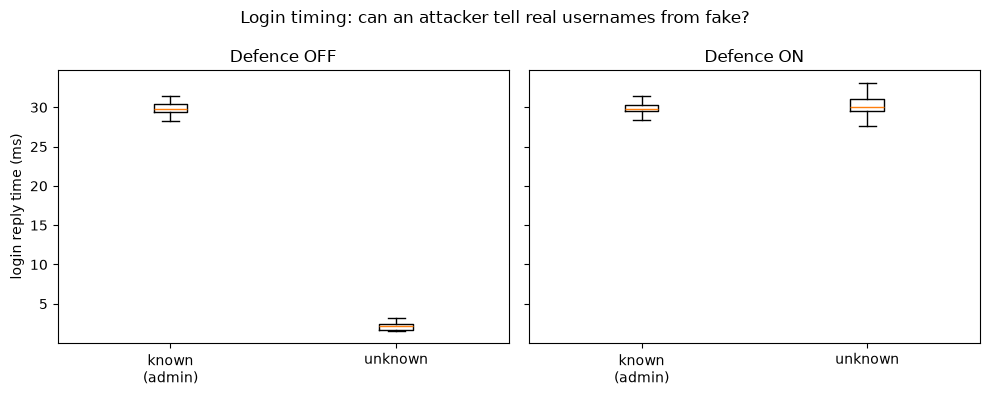

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, cond, title in [(axes[0], "off", "Defence OFF"),
                        (axes[1], "on", "Defence ON")]:
    sub = df[df.defence == cond]
    ax.boxplot([sub[sub.username == "known"].ms, sub[sub.username == "unknown"].ms], showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["known\n(admin)", "unknown"])
    ax.set_title(title)


axes[0].set_ylabel("login reply time (ms)")
fig.suptitle("Login timing: can an attacker tell real usernames from fake?")
fig.tight_layout()
fig.savefig(OUT / "login_timing.png", dpi=300)
plt.show()

## 6. What the numbers say

With the defence off, a known username is slower than an unknown one by about one argon2
verify. The gap is far larger than localhost noise, so an attacker who times the replies
can sort real usernames from fake ones. With the defence on, the gap drops to noise,
because an unknown username now runs one argon2 verify against a fixed dummy hash as well.

What the defence does not fix:

- `POST /api/register` still answers 409 when a username is taken. That is a separate way
  to enumerate usernames, and this defence does not touch it
- A patient attacker can average many more samples and pull a smaller signal out of the
  jitter from other side channels like garbage collection or memory timings. 
  `LOGIN_RATE_LIMIT`, a separate defence, which caps how many samples they can get, 
  and over a real network the jitter helps the defender too.

Cost: one extra argon2 verify on each failed login for an unknown username, which is tens
of milliseconds of CPU and a short-lived ~64 MB of memory. The normal correct-login path
pays nothing extra therefore a user would not notice the difference.